# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import CVBrCTDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Aerial dataset

### Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/cvbrct/aerial/",
    "csv_file": "/home/dragik/data/FAIR_EO/cvbrct/aerial/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = CVBrCTDataset(dataset_config)

### Show images from the dataset

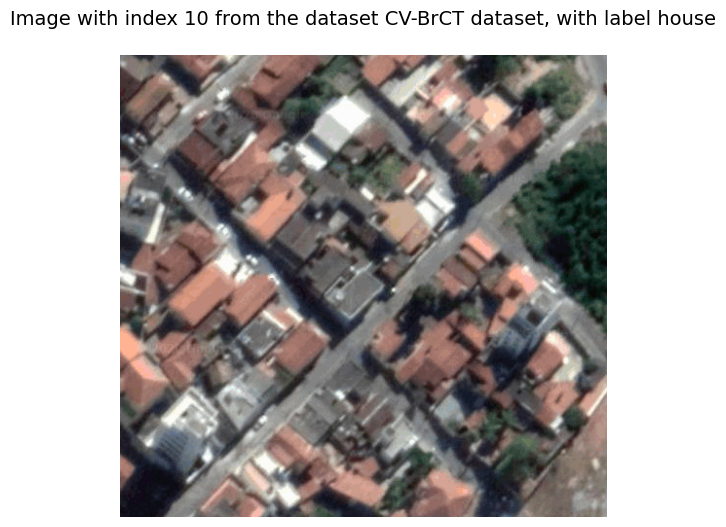

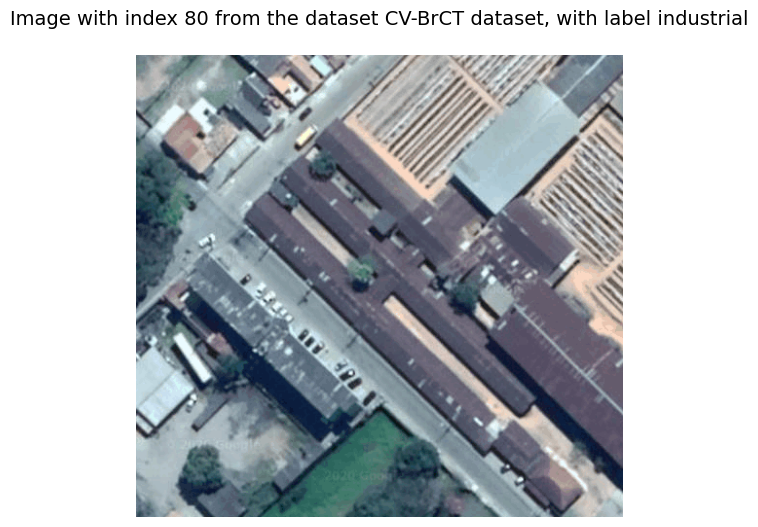

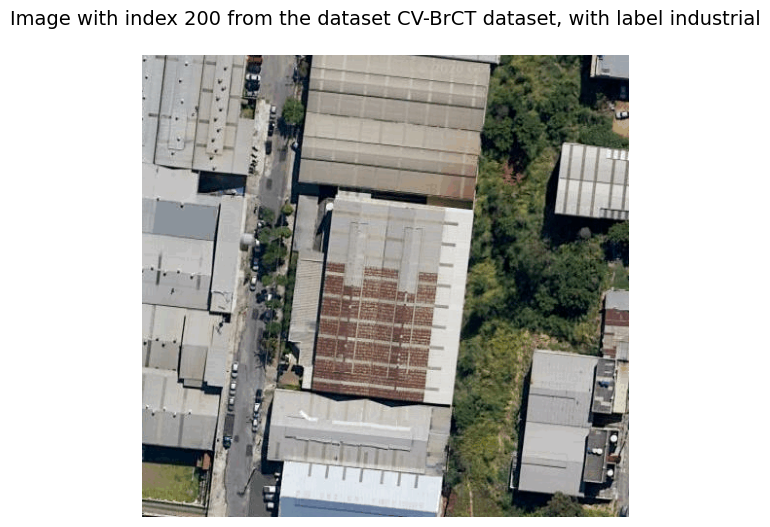

In [7]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

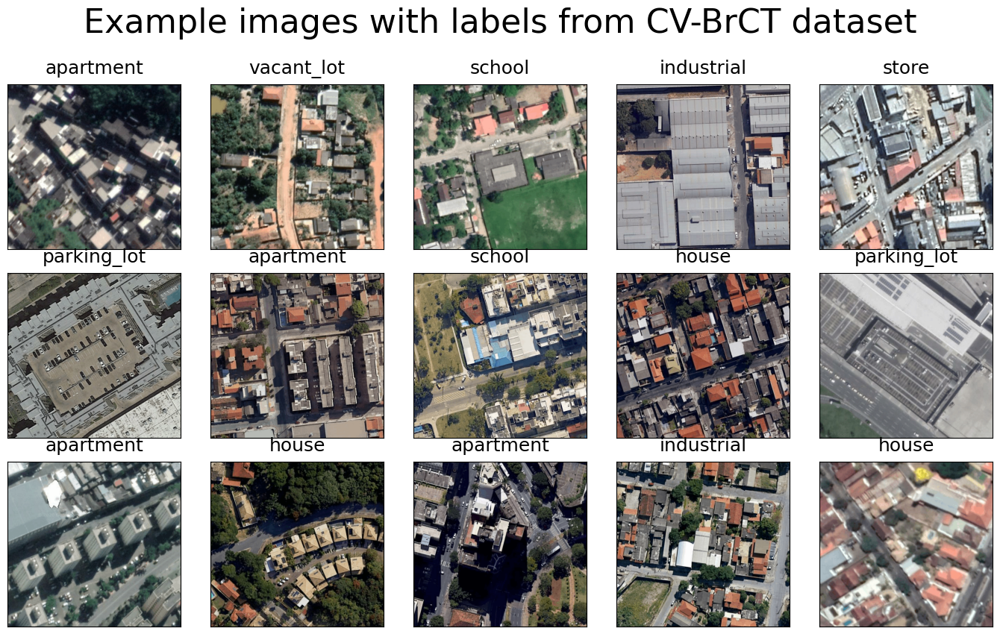

In [8]:
fig4 = dataset.show_batch(15)

### Inspect the data

In [9]:
dataset.show_samples()

,File name,Label
0,school/x2dD2WKwZeg357h4wwvK7Q.png,school
1,parking_lot/o2HLPWzG8hbmJ5vu0K4-PA.png,parking_lot
2,industrial/aqviofGY0Bnu9Nbi3IT9Pw.png,industrial
3,house/8lyYsoPQh6ftosD0bf5_gQ.png,house
4,school/kRh9NI4eiE7d6nvZGgL4zA.png,school
5,school/3Km4kk0MnZX24vbwsbjo4A.png,school
6,industrial/gl0hkmF_26JGkUPaJxZ2zA.png,industrial
7,house/Y_UAgOW376dzPv8WN07DKA.png,house
8,house/yBFOzwNgGMOWIus9Uhb15w.png,house
9,store/yFCWhHN3K4rJB42eqBWcRg.png,store


In [10]:
dataset.data_distribution_table()

,Label,Count
0,apartment,4208
1,hospital,290
2,house,6099
3,industrial,2353
4,parking_lot,1005
5,religious,1364
6,school,2095
7,store,1562
8,vacant_lot,360


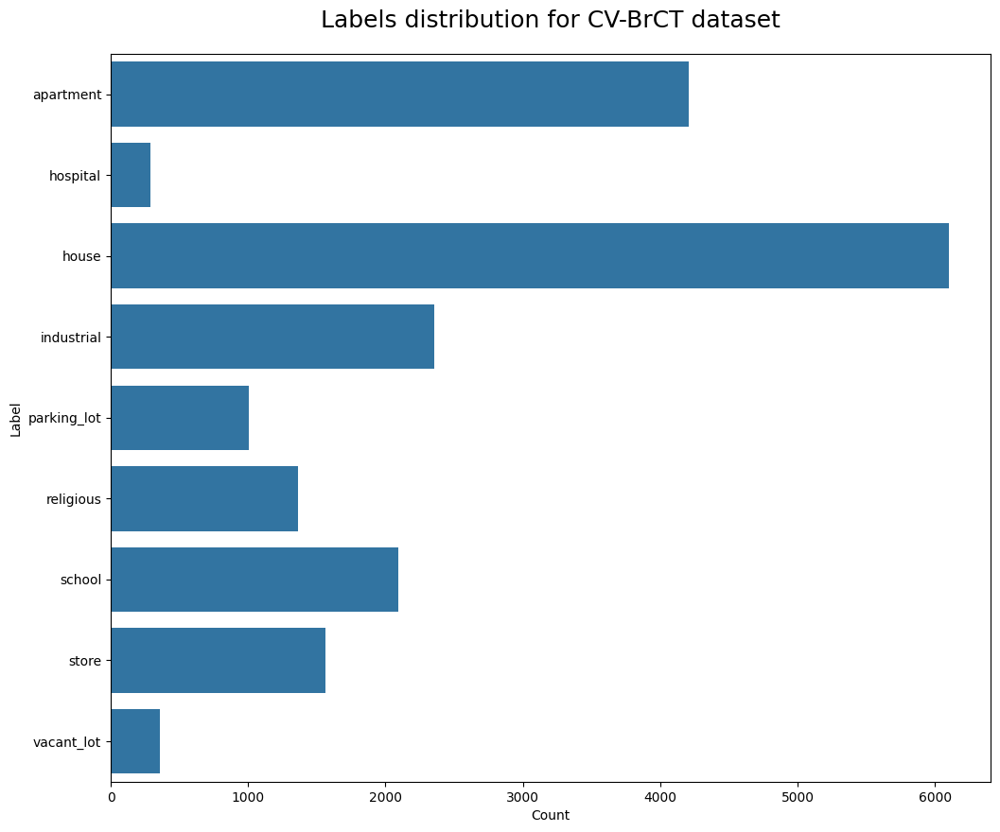

In [11]:
fig = dataset.data_distribution_barchart()

### Load train and validation splits

In [8]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/cvbrct/aerial/",
    "csv_file": "/home/dragik/data/FAIR_EO/cvbrct/aerial/train.csv",
}

train_dataset = CVBrCTDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/cvbrct/aerial/",
    "csv_file": "/home/dragik/data/FAIR_EO/cvbrct/aerial/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = CVBrCTDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(19336, 2417)

### Setup and create the model for training

In [9]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/cvbrct/aerial/"
model_config = {
    "num_classes": 9, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-20 09:58:32,606 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-20 09:58:32,932 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


### Training and validation

In [10]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-20 09:58:33,866 INFO Starting training.
training: 100%|██████████| 605/605 [02:36<00:00,  3.86it/s]
2025-05-20 10:01:10,535 INFO epoch: 1, time: 157, loss:  0.84611
testing on train set: 100%|██████████| 605/605 [01:05<00:00,  9.25it/s]
2025-05-20 10:02:18,062 INFO Accuracy:0.8144393876706661, Precision Micro:0.8144393876706661, Precision Macro:0.8143695197419824, Precision Weighted:0.8324423362556959, Precision per Class:[0.89449786 0.92857143 0.93057456 0.80449961 0.94948454 0.56018519
 0.76731553 0.5245     0.96969697], Recall Micro:0.8144393876706661, Recall Macro:0.7097985829621076, Recall Weighted:0.8144393876706661, Recall per Class:[0.79586502 0.08965517 0.89227742 0.88142796 0.91641791 0.70967742
 0.80906921 0.6715749  0.62222222], F1_score Micro:0.8144393876706657, F1_score Macro:0.7168355512705107, F1_score Weighted:0.8151586125359924, F1_score per Class:[0.84230382 0.16352201 0.91102369 0.84120868 0.93265823 0.62613195
 0.78763941 0.58899495 0.75803723]
testing on v

0.2612697880547131

### Test the model

In [11]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/cvbrct/aerial/",
    "csv_file": "/home/dragik/data/FAIR_EO/cvbrct/aerial/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = CVBrCTDataset(test_dataset_config)
model_path = "/home/dragik/data/FAIR_EO/experiments/cvbrct/aerial/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-20 11:14:30,968 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/cvbrct/aerial/checkpoint.pth.tar
2025-05-20 11:14:31,607 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/cvbrct/aerial/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 151/151 [00:15<00:00,  9.49it/s]


[{'Accuracy': 0.8480960264900662},
 {'Precision Micro': 0.8480960264900662,
  'Precision Macro': 0.8249312429180579,
  'Precision Weighted': 0.853954181840884,
  'Precision per Class': array([0.898     , 0.6875    , 0.92829706, 0.92016807, 0.96396396,
         0.59292035, 0.71130952, 0.74305556, 0.97916667])},
 {'Recall Micro': 0.8480960264900662,
  'Recall Macro': 0.7802536545032207,
  'Recall Weighted': 0.8480960264900663,
  'Recall per Class': array([0.8997996 , 0.42307692, 0.95520422, 0.74744027, 0.89915966,
         0.70526316, 0.86281588, 0.60795455, 0.92156863])},
 {'F1_score Micro': 0.8480960264900657,
  'F1_score Macro': 0.7957564152968419,
  'F1_score Weighted': 0.8474179154869591,
  'F1_score per Class': array([0.8988989 , 0.52380952, 0.94155844, 0.82485876, 0.93043478,
         0.64423077, 0.77977162, 0.66875   , 0.94949495])}]

### Predictions

2025-05-20 11:15:09,023 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/cvbrct/aerial/checkpoint.pth.tar
2025-05-20 11:15:09,634 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/cvbrct/aerial/checkpoint.pth.tar at epoch 11


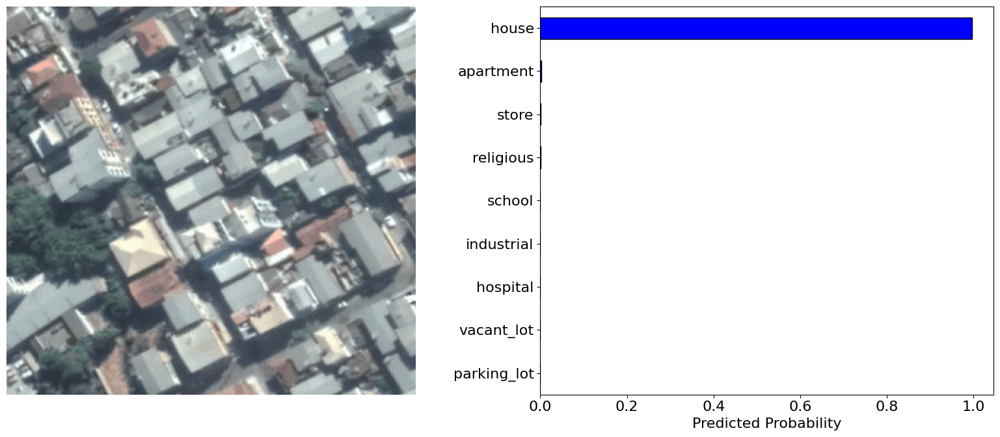

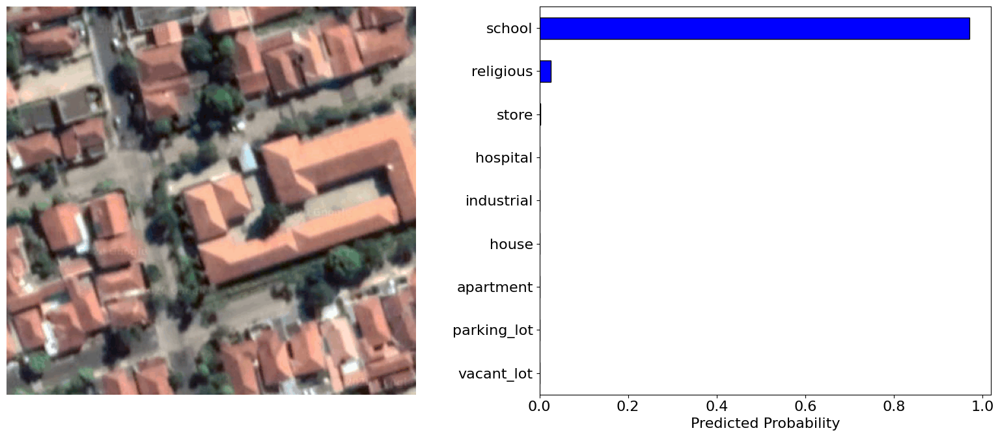

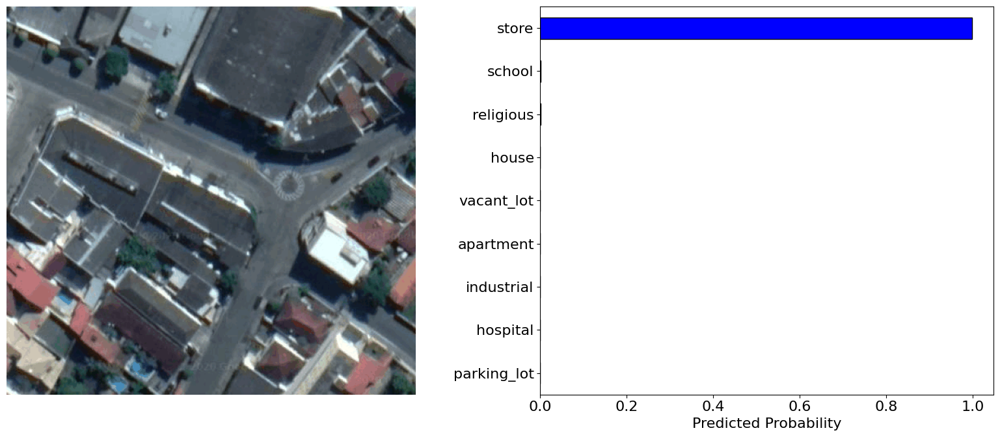

In [13]:
labels = ["apartment","hospital","house","industrial","parking_lot","religious","school","store","vacant_lot"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/cvbrct/aerial/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/cvbrct/aerial/house/t716lgx_UP924TJq07_Mug.png')
image = image[:,:,0:3]
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/cvbrct/aerial/school/pSz0kDuG_ztq7X_KHy4NxQ.png')
image = image[:,:,0:3]
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/cvbrct/aerial/store/e_kvPcOtSEiZIkEXoeHsog.png')
image = image[:,:,0:3]
fig = model.predict_image(image, labels, transform)

## Street dataset

### Load the dataset

In [16]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/cvbrct/street/",
    "csv_file": "/home/dragik/data/FAIR_EO/cvbrct/street/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = CVBrCTDataset(dataset_config)

### Show images from the dataset

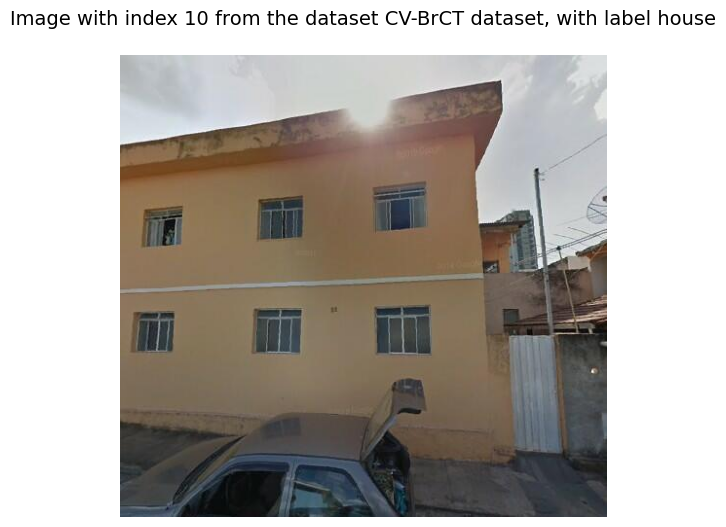

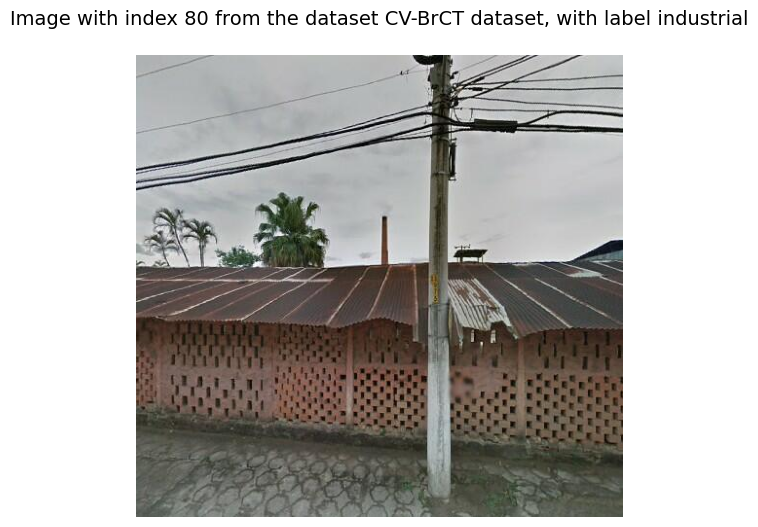

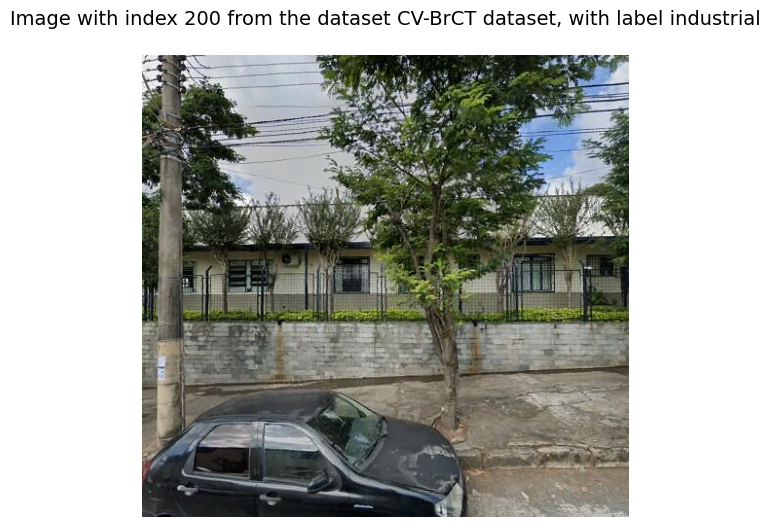

In [17]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

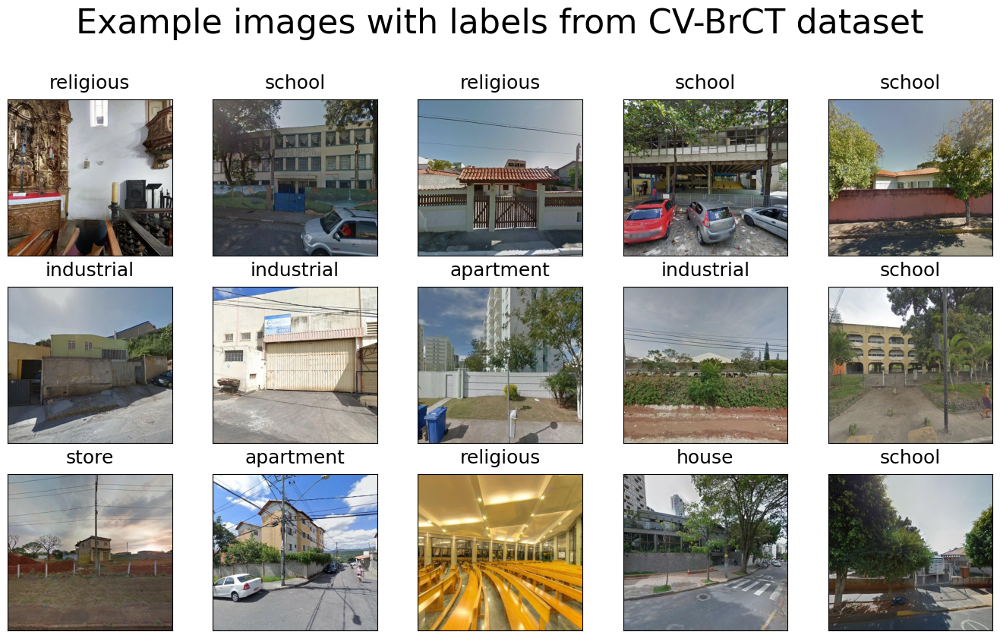

In [18]:
fig4 = dataset.show_batch(15)

### Inspect the data

In [19]:
dataset.show_samples()

,File name,Label
0,school/x2dD2WKwZeg357h4wwvK7Q.jpg,school
1,parking_lot/o2HLPWzG8hbmJ5vu0K4-PA.jpg,parking_lot
2,industrial/aqviofGY0Bnu9Nbi3IT9Pw.jpg,industrial
3,house/8lyYsoPQh6ftosD0bf5_gQ.jpg,house
4,school/kRh9NI4eiE7d6nvZGgL4zA.jpg,school
5,school/3Km4kk0MnZX24vbwsbjo4A.jpg,school
6,industrial/gl0hkmF_26JGkUPaJxZ2zA.jpg,industrial
7,house/Y_UAgOW376dzPv8WN07DKA.jpg,house
8,house/yBFOzwNgGMOWIus9Uhb15w.jpg,house
9,apartment/z_hJMSRrtutnbnheLCP_rg.jpg,apartment


In [20]:
dataset.data_distribution_table()

,Label,Count
0,apartment,4237
1,hospital,290
2,house,6099
3,industrial,2353
4,parking_lot,1005
5,religious,1364
6,school,2095
7,store,1533
8,vacant_lot,360


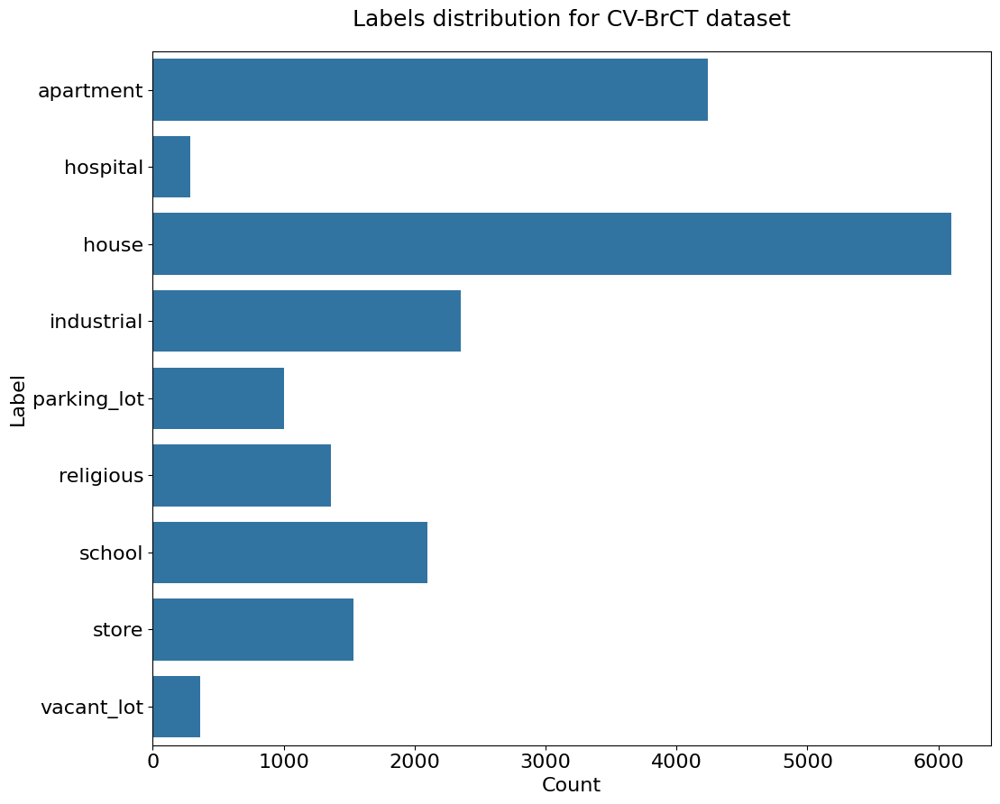

In [23]:
dataset.data_distribution_barchart();

### Load train and validation splits

In [24]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/cvbrct/street/",
    "csv_file": "/home/dragik/data/FAIR_EO/cvbrct/street/train.csv",
}

train_dataset = CVBrCTDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/cvbrct/street/",
    "csv_file": "/home/dragik/data/FAIR_EO/cvbrct/street/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = CVBrCTDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(19336, 2417)

### Setup and create the model for training

In [25]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/cvbrct/street/"
model_config = {
    "num_classes": 9, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-20 11:18:59,116 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-20 11:18:59,490 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


### Training and validation

In [26]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-20 11:19:01,264 INFO Starting training.
training: 100%|██████████| 605/605 [05:20<00:00,  1.89it/s]
2025-05-20 11:24:22,021 INFO epoch: 1, time: 321, loss:  1.19568
testing on train set: 100%|██████████| 605/605 [01:57<00:00,  5.14it/s]
2025-05-20 11:26:21,600 INFO Accuracy:0.6970417873396773, Precision Micro:0.6970417873396773, Precision Macro:0.7170540334914138, Precision Weighted:0.7201023618558506, Precision per Class:[0.73321594 1.         0.79533555 0.49298202 0.74773869 0.76772616
 0.73027799 0.64867968 0.53753027], Recall Micro:0.6970417873396773, Recall Macro:0.5680311571897048, Recall Weighted:0.6970417873396774, Recall per Class:[0.78616946 0.00344828 0.82193802 0.85082873 0.74029851 0.46041056
 0.46396181 0.36855838 0.61666667], F1_score Micro:0.6970417873396767, F1_score Macro:0.569977767656148, F1_score Weighted:0.6860421449665435, F1_score per Class:[0.75876993 0.00687285 0.808418   0.62425943 0.744      0.5756187
 0.56742557 0.47004992 0.57438551]
testing on val

0.18430503674489582

### Test the model

In [27]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/cvbrct/street/",
    "csv_file": "/home/dragik/data/FAIR_EO/cvbrct/street/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = CVBrCTDataset(test_dataset_config)
model_path = "/home/dragik/data/FAIR_EO/experiments/cvbrct/street/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-20 12:27:03,225 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/cvbrct/street/checkpoint.pth.tar
2025-05-20 12:27:04,001 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/cvbrct/street/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 151/151 [00:17<00:00,  8.53it/s]


[{'Accuracy': 0.6924668874172185},
 {'Precision Micro': 0.6924668874172185,
  'Precision Macro': 0.6105252435168833,
  'Precision Weighted': 0.6868400542027221,
  'Precision per Class': array([0.70566728, 0.2       , 0.81538462, 0.67730496, 0.75728155,
         0.6031746 , 0.56716418, 0.46875   , 0.7       ])},
 {'Recall Micro': 0.6924668874172185,
  'Recall Macro': 0.5649129926031196,
  'Recall Weighted': 0.6924668874172186,
  'Recall per Class': array([0.77665996, 0.09615385, 0.83794466, 0.65187713, 0.65546218,
         0.6       , 0.54873646, 0.50561798, 0.41176471])},
 {'F1_score Micro': 0.692466887417218,
  'F1_score Macro': 0.5808090294487777,
  'F1_score Weighted': 0.6877954267987659,
  'F1_score per Class': array([0.7394636 , 0.12987013, 0.82651072, 0.66434783, 0.7027027 ,
         0.60158311, 0.55779817, 0.48648649, 0.51851852])}]

### Predictions

2025-05-20 12:27:21,728 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/cvbrct/street/checkpoint.pth.tar
2025-05-20 12:27:22,451 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/cvbrct/street/checkpoint.pth.tar at epoch 11


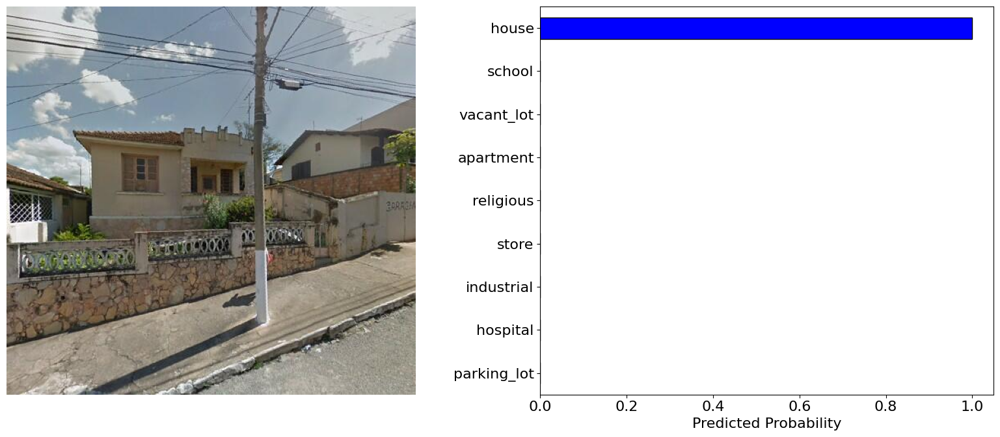

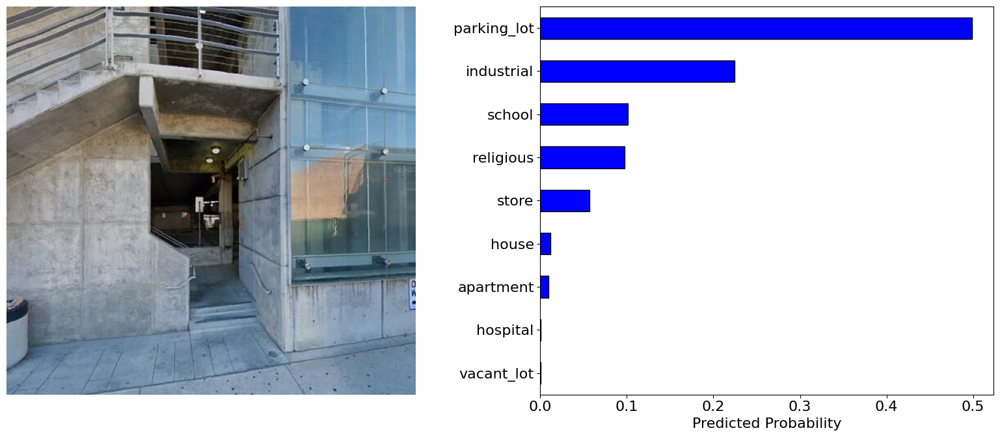

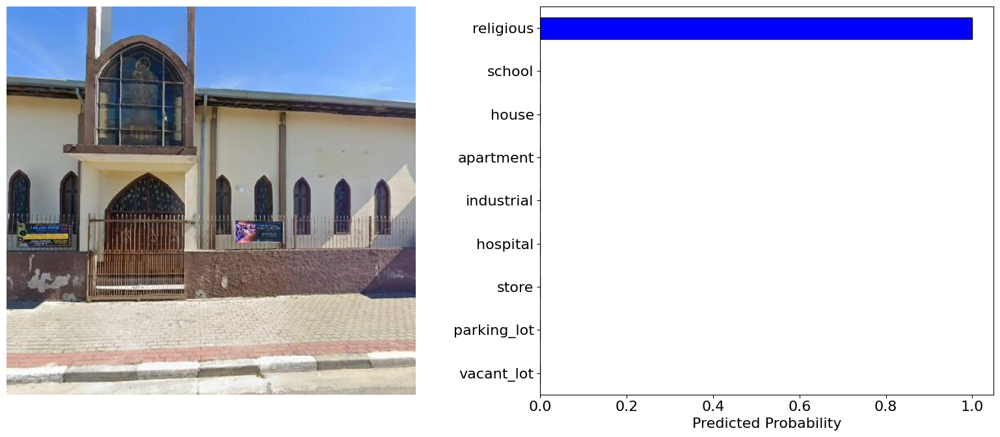

In [28]:
labels = ["apartment","hospital","house","industrial","parking_lot","religious","school","store","vacant_lot"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/cvbrct/street/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/cvbrct/street/house/frt3dOiLAhq8fuyQyswfmw.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/cvbrct/street/parking_lot/JR4p7Vd0mwpymUvYwndODw.jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/cvbrct/street/religious/OTu6v_DNXDqdjWbmNQuoyw.jpg')
fig = model.predict_image(image, labels, transform)